In [1]:
!pip install pypsa matplotlib cartopy highspy pandas numpy

In [2]:
import pypsa
import pandas as pd
import numpy as np

Prepare input data

In [3]:
# Obtained from IEMOP Data from 2023
filename = "/content/PyPSA_Dataset_Bohol.xlsx"
buses_df = pd.read_excel(filename, sheet_name="buses")
loads_df = pd.read_excel(filename, sheet_name="loads")
carriers_df = pd.read_excel(filename, sheet_name="carriers")
generators_df = pd.read_excel(filename, sheet_name="generators")
lines_df = pd.read_excel(filename, sheet_name="lines")

In [4]:
# Obtain from Renewable Energy Ninja: https://www.renewables.ninja/; Assumed same weather data for 2023
loads_t_df = pd.read_excel(filename, sheet_name="loads_t", index_col=0, parse_dates=True, date_format='%m/%d/%y %H:%M')
generators_t_df = pd.read_excel(filename, sheet_name="generators_t", index_col=0, parse_dates=True, date_format='%m/%d/%y %H:%M')

In [5]:
loads_t_df.index = pd.to_datetime(loads_t_df.index)
generators_t_df.index = pd.to_datetime(generators_t_df.index)

Build PyPSA network

In [6]:
n = pypsa.Network()

In [7]:
freq = 2 # temporal resolution
n.set_snapshots(pd.date_range(start="2023-01-02 00:00:00", end="2023-01-02 23:00:00", freq=f'{freq}h'))

In [8]:
n.snapshots

DatetimeIndex(['2023-01-02 00:00:00', '2023-01-02 02:00:00',
               '2023-01-02 04:00:00', '2023-01-02 06:00:00',
               '2023-01-02 08:00:00', '2023-01-02 10:00:00',
               '2023-01-02 12:00:00', '2023-01-02 14:00:00',
               '2023-01-02 16:00:00', '2023-01-02 18:00:00',
               '2023-01-02 20:00:00', '2023-01-02 22:00:00'],
              dtype='datetime64[ns]', name='snapshot', freq='2h')

In [9]:
n.snapshot_weightings = pd.Series(freq, index=n.snapshots)

In [10]:
carriers_df

,name,color,co2_emissions,VOM,FOM,fuel,investment,efficiency,lifetime
0,Diesel,#B41E25,0.2571,6.3493,2.5656,52.91110,3.629700e+05,0.35,25
1,Hydro,#1E81D4,0.0000,0.0000,1.0000,0.00000,2.274818e+06,0.90,80
2,Solar,#FDB324,0.0000,0.0106,1.5780,0.00000,8.098118e+05,1.00,35
3,Wind,#3BBFE5,0.0000,1.5873,1.2514,0.00000,1.183912e+06,1.00,27
4,Battery,#814ad4,0.0000,0.0000,0.2000,0.00000,2.455074e+05,0.95,20
5,Grid,#b01787,0.1100,0.0000,0.0000,42.73002,1.396283e+04,1.00,40


In [11]:
for carrier in carriers_df.itertuples():
    n.add("Carrier",
          carrier.name,
          co2_emissions=carrier.co2_emissions,
          color=carrier.color,
          vom=carrier.VOM + (carrier.fuel/carrier.efficiency),
          cap=(1+carrier.FOM)*(carrier.investment/(carrier.lifetime*365.25)),
          eff=carrier.efficiency)

n.add("Carrier", "AC")

In [12]:
for bus in buses_df.itertuples():
    n.add("Bus",
          bus.name,
          x=bus.x,
          y=bus.y,
          v_nom=bus.v_nom,
          carrier="AC")

In [13]:
for line in lines_df.itertuples():
    n.add("Line",
          line.name,
          bus0=line.bus0,
          bus1=line.bus1,
          s_nom=line.s_nom,
          x=line.x,
          r=line.r,
          carrier="AC")

In [14]:
for load in loads_df.itertuples():
    n.add("Load",
          load.name,
          bus=load.bus)

In [15]:
n.loads_t.p_set = loads_t_df.resample(f'{freq}h').mean()

In [16]:
for generator in generators_df.itertuples():
    n.add("Generator",
          generator.name,
          bus=generator.bus,
          carrier=generator.carrier,
          p_nom=generator.p_nom,
          marginal_cost= n.carriers.loc[generator.carrier,"vom"],
          capital_cost=n.carriers.loc[generator.carrier,"cap"],
          efficiency=n.carriers.loc[generator.carrier,"eff"])

In [17]:
n.generators_t.p_max_pu = generators_t_df.resample('2h').mean()

Scenario 1: Transmission Grid Capacity Decrease

In [ ]:
raise RuntimeError("Stopping execution here.")

In [ ]:
gridcap = n.generators.loc["Grid_electricity","p_nom"]

In [ ]:
n.generators.loc["Grid_electricity","p_nom"] = gridcap*0.3

Scenario 2: Transmission Grid Failure / Disconnection Scenario

In [ ]:
raise RuntimeError("Stopping execution here.")

In [ ]:
n.remove("Generator", "Grid_electricity")

Add extendable generation (solar and wind)

In [ ]:
n.add("Generator",
      "SOLAR_BOHOL",
      bus="07TAPAL",
      carrier="Solar",
      p_nom_extendable=True,
      marginal_cost= n.carriers.loc["Solar","marginal_cost"],
      capital_cost=n.carriers.loc["Solar","capital_cost"],
      efficiency=n.carriers.loc["Solar","efficiency"])

n.add("Generator",
      "WIND_BOHOL",
      bus="07UBAY",
      carrier="Wind",
      p_nom_extendable=True,
      marginal_cost= n.carriers.loc["Wind","marginal_cost"],
      capital_cost=n.carriers.loc["Wind","capital_cost"],
      efficiency=n.carriers.loc["Wind","efficiency"])

Index(['WIND_BOHOL'], dtype='object')

Add extendable storage unit (battery)

In [ ]:
n.add("StorageUnit",
      "BATTERY_BOHOL",
      bus="07UBAY",
      carrier="Battery",
      p_nom_extendable=True,
      cyclic_state_of_charge=True,
      marginal_cost= n.carriers.loc["Battery","marginal_cost"],
      capital_cost= n.carriers.loc["Battery","capital_cost"],
      max_hours=4,
      efficiency_dispatch=n.carriers.loc["Battery","efficiency"],
      efficiency_store=1)

Index(['BATTERY_BOHOL'], dtype='object')

In [ ]:
n

PyPSA Network 'Unnamed Network'
-------------------------------
Components:
 - Bus: 3
 - Carrier: 7
 - Generator: 14
 - Line: 3
 - Load: 2
 - StorageUnit: 1
 - SubNetwork: 1
Snapshots: 12

Optimize and visualize network

In [ ]:
raise RuntimeError("Stopping execution here.")

{'nodes': {'Bus': <matplotlib.collections.PatchCollection at 0x7e0784605a60>},
 'branches': {'Line': <matplotlib.collections.LineCollection at 0x7e07848d71a0>},
 'flows': {}}

/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning:

Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_boundary_lines_land.zip

/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning:

Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip



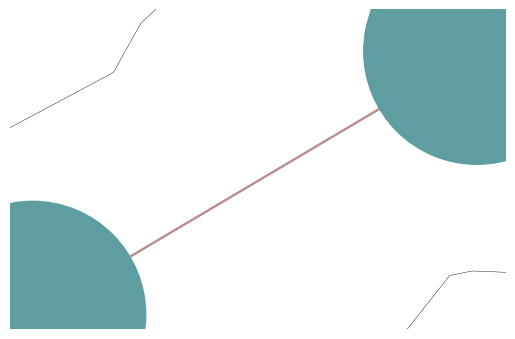

In [18]:
n.plot()

In [19]:
n

PyPSA Network 'Unnamed Network'
-------------------------------
Components:
 - Bus: 3
 - Carrier: 7
 - Generator: 13
 - Line: 3
 - Load: 2
Snapshots: 12

In [20]:
n.optimize(solver_name="highs")

/tmp/ipykernel_5438/3144390136.py:1: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['SOLAR_BOHOL', 'WIND_BOHOL'], dtype='object')


('ok', 'optimal')

In [21]:
n.statistics()

Optimal Capacity  Installed Capacity      Supply  \
Generator Diesel              45.2                45.2     0.00000   
          Grid               138.0               138.0  1278.06428   
          Hydro                9.9                 9.9   237.60000   
Line      AC                 276.0               276.0     0.00000   
Load      -                    0.0                 0.0     0.00000   

                  Withdrawal  Energy Balance  Transmission  Capacity Factor  \
Generator Diesel     0.00000         0.00000       0.00000         0.000000   
          Grid       0.00000      1278.06428       0.00000         0.385889   
          Hydro      0.00000       237.60000       0.00000         1.000000   
Line      AC       754.13475      -754.13475     754.13475         0.113849   
Load      -       1515.66428     -1515.66428       0.00000              NaN   

                  Curtailment  Capital Expenditure  Operational Expenditure  \
Generator Diesel   1084.80000           6406.36316                  0.00000   
          Grid     2033.93572            131.88706              54611.71217   
          Hydro       0.00000           1541.45758                  0.00000   
Line      AC          0.00000              0.00000                  0.00000   
Load      -           0.00000              0.00000                  0.00000   

                      Revenue  Market Value  
Generator Diesel      0.00000           NaN  
          Grid    54611.71217     42.730019  
          Hydro   10152.65275     42.730020  
Line      AC     -32224.19274    -42.730022  
Load      -      -64764.36492    -42.730019

In [22]:
n.buses_t.marginal_price.mean()

,0
name,
07CORELLA,42.73002
07TAPAL,42.73002
07UBAY,42.73002


In [23]:
n.generators.capital_cost

,capital_cost
name,
07TPLPB4_U01,141.733698
07TPLPB4_U02,141.733698
07TPLPB4_U03,141.733698
07TPLPB4_U04,141.733698
07BDPP_U01,141.733698
07BDPP_U02,141.733698
07BDPP_U03,141.733698
07BDPP_U04,141.733698
07JANOPO_G01,155.702786


In [24]:
n.generators.marginal_cost

,marginal_cost
name,
07TPLPB4_U01,157.523871
07TPLPB4_U02,157.523871
07TPLPB4_U03,157.523871
07TPLPB4_U04,157.523871
07BDPP_U01,157.523871
07BDPP_U02,157.523871
07BDPP_U03,157.523871
07BDPP_U04,157.523871
07JANOPO_G01,0.000000


<Axes: xlabel='snapshot'>

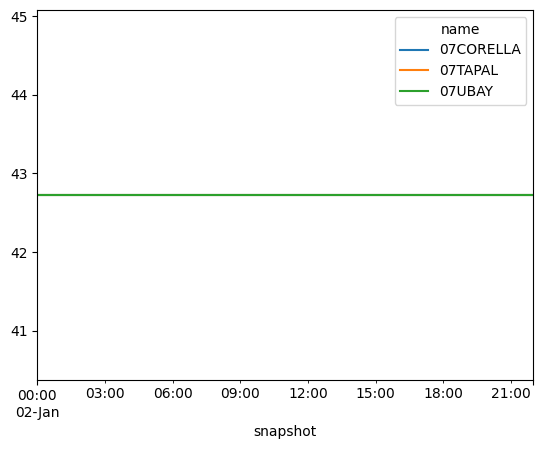

In [25]:
n.buses_t.marginal_price.plot()

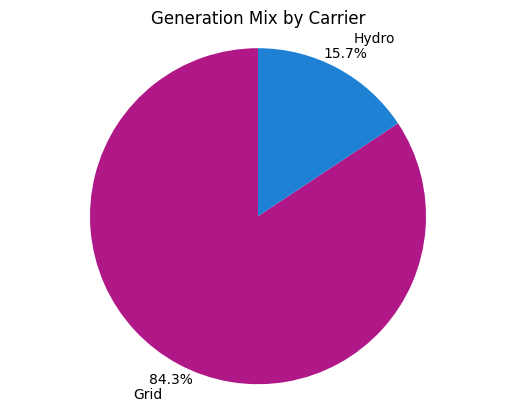

In [26]:
# prompt: generate me the percentages on the generation mix of different carriers. plot as a pie chart with values outside. make it a function and use the colors in the n.carriers

import matplotlib.pyplot as plt

def plot_generation_mix_pie(network):
  """
  Plots the generation mix of different carriers as a pie chart with percentages outside.

  Args:
    network (pypsa.Network): The PyPSA network object.
  """
  # Calculate total generation per carrier
  generation_by_carrier = network.generators_t.p.sum().groupby(network.generators.carrier).sum()

  # Calculate percentages
  total_generation = generation_by_carrier.sum()
  percentages = generation_by_carrier / total_generation * 100

  # Get carrier colors
  carrier_colors = network.carriers.color.dropna().to_dict()

  # Filter out carriers with zero generation
  percentages = percentages[percentages > 0]
  labels = percentages.index
  sizes = percentages.values
  colors = [carrier_colors.get(label, 'gray') for label in labels] # Use gray for carriers without a specified color

  fig1, ax1 = plt.subplots()
  patches, texts, autotexts = ax1.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%',
                                      startangle=90, pctdistance=1.1, labeldistance=1.2)

  # Ensure text is visible
  for text in texts:
      text.set_color('black')
  for autotext in autotexts:
      autotext.set_color('black')

  ax1.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
  plt.title("Generation Mix by Carrier")
  plt.show()

# Call the function with your network object
plot_generation_mix_pie(n)

/tmp/ipykernel_5438/1716586672.py:14: FutureWarning:

DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.

/tmp/ipykernel_5438/1716586672.py:17: FutureWarning:

DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.



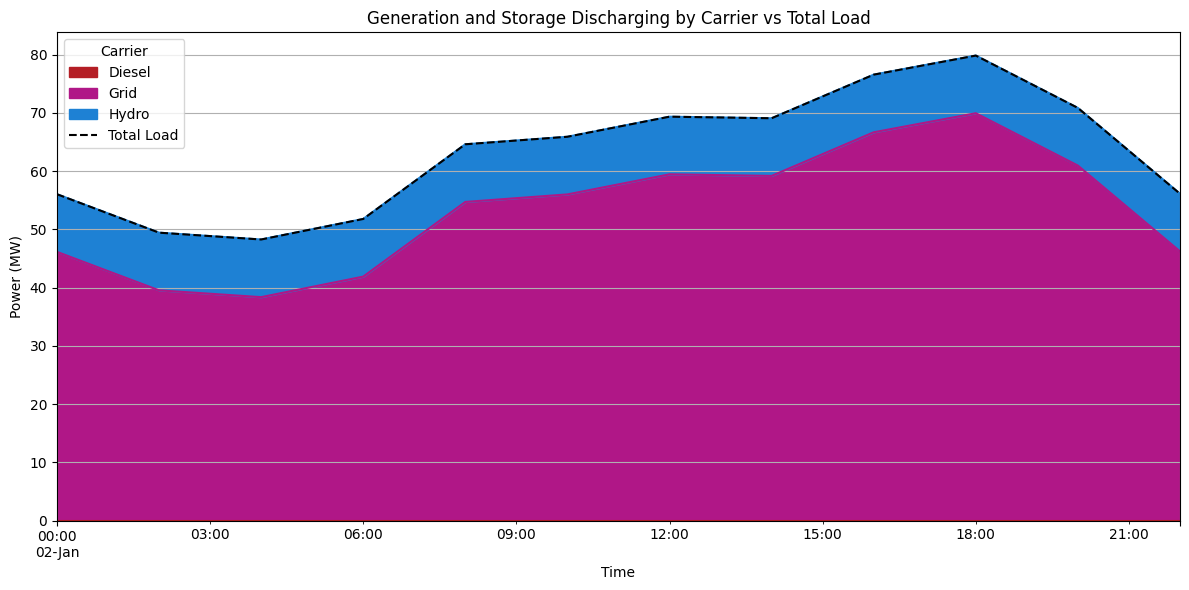

In [27]:
# prompt: make me a function that makes a stacked plot for the different generator and storage unit (discharging and charging) carriers. Use the colors in the n.carriers. Also, add a line plot for the total load.

import matplotlib.pyplot as plt

def plot_generation_and_load(n):
    """
    Makes a stacked plot for the different generator and storage unit (discharging) carriers.
    Uses the colors in the n.carriers. Also, adds a line plot for the total load.

    Args:
        n (pypsa.Network): The optimized PyPSA network.
    """
    # Get dispatched generation by carrier
    generation_by_carrier = n.generators_t.p.groupby(n.generators.carrier, axis=1).sum()

    # Get dispatched storage units (discharging is positive) by carrier
    storage_discharging_by_carrier = n.storage_units_t.p.groupby(n.storage_units.carrier, axis=1).sum()
    storage_discharging_by_carrier = storage_discharging_by_carrier.clip(lower=0) # Keep only discharging (positive values)

    # Combine generation and storage discharging
    combined_output = pd.concat([generation_by_carrier, storage_discharging_by_carrier], axis=1).fillna(0)

    # Get total load
    total_load = n.loads_t.p.sum(axis=1)

    # Get colors from carriers
    carrier_colors = n.carriers.color.to_dict()

    # Plotting
    fig, ax = plt.subplots(figsize=(12, 6))

    # Stacked plot of generation and storage discharging by carrier
    combined_output.plot(kind='area', stacked=True, ax=ax, color=carrier_colors)

    # Plot total load as a line
    total_load.plot(ax=ax, color='black', linestyle='--', label='Total Load')

    ax.set_xlabel("Time")
    ax.set_ylabel("Power (MW)")
    ax.set_title("Generation and Storage Discharging by Carrier vs Total Load")
    ax.legend(title="Carrier")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Call the function with your network
plot_generation_and_load(n)


/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning:

Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip



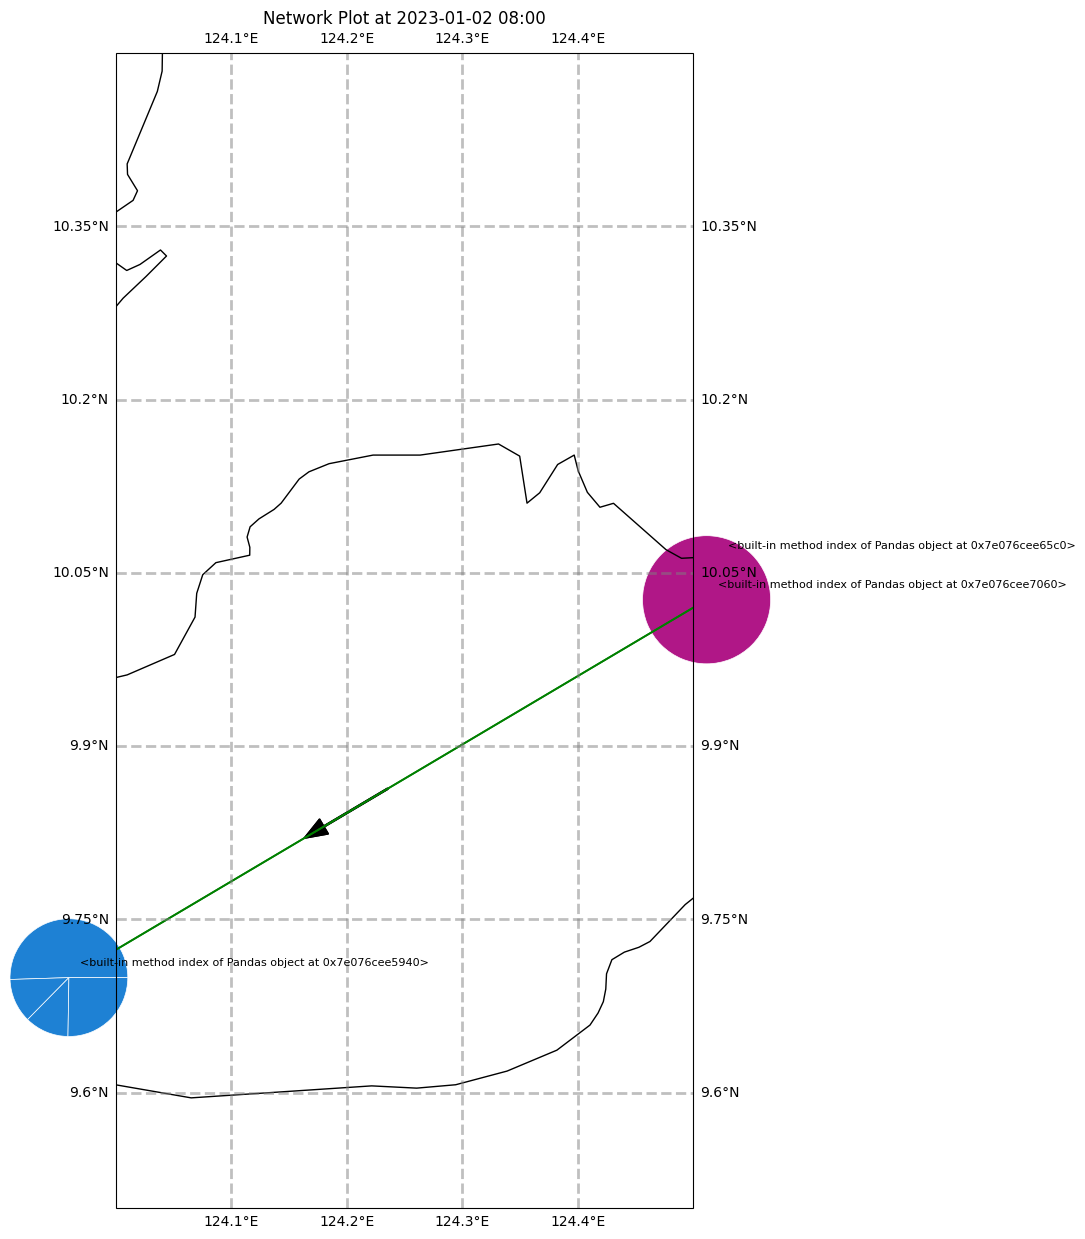

In [28]:
# prompt: make me a function that gives me a map plot showing the buses (with pie chart of generation capacities) and transmission lines (with loading as color, and direction of flow) at specific time input for a network.

import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

def plot_network_at_time(n, time_snapshot):
    """
    Plots the PyPSA network at a specific time snapshot.
    Shows buses with pie charts of generation capacities, and transmission lines
    with loading as color and direction of flow.

    Args:
        n (pypsa.Network): The optimized PyPSA network.
        time_snapshot (pandas.Timestamp or str): The time snapshot to plot.
    """
    # Ensure the time_snapshot is a pandas Timestamp
    if isinstance(time_snapshot, str):
        time_snapshot = pd.to_datetime(time_snapshot)

    # Check if the snapshot exists in the network
    if time_snapshot not in n.snapshots:
        print(f"Error: Time snapshot '{time_snapshot}' not found in the network.")
        print("Available snapshots:", n.snapshots)
        return

    fig = plt.figure(figsize=(15, 15))
    ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
    ax.set_extent([124.0, 124.5, 9.5, 10.5], crs=ccrs.PlateCarree()) # Adjust extent for Bohol

    # Plot buses
    for bus in n.buses.itertuples():
        ax.plot(bus.x, bus.y, 'o', color='black', markersize=5, transform=ccrs.PlateCarree())
        ax.text(bus.x + 0.01, bus.y + 0.01, bus.index, fontsize=8, transform=ccrs.PlateCarree())

        # Create pie chart for generation at this bus
        bus_generators = n.generators[n.generators.bus == bus.Index]
        if not bus_generators.empty:
            generation_at_bus = n.generators_t.p.loc[time_snapshot, bus_generators.index].sum()
            if generation_at_bus > 0:
                generation_shares = n.generators_t.p.loc[time_snapshot, bus_generators.index]
                generation_shares = generation_shares[generation_shares > 0] # Only include generators with output

                if not generation_shares.empty:
                     # Get colors from carriers
                    carrier_colors = n.carriers.color.to_dict()
                    colors = [carrier_colors.get(n.generators.loc[gen_name].carrier, 'gray') for gen_name in generation_shares.index]

                    # Scale pie chart size based on total generation at the bus
                    total_generation = generation_shares.sum()
                    pie_radius = 0.05 + total_generation / (500) * 0.05  # Adjust scaling factor as needed

                    # Create the pie chart as an annotation
                    ax.pie(generation_shares, colors=colors, radius=pie_radius, center=(bus.x, bus.y), frame=True,
                           wedgeprops={"edgecolor":"white",'linewidth': 0.5, 'antialiased': True})


    # Plot lines with loading and direction
    # Calculate line loading percentage and direction
    line_loading = n.lines_t.p0.loc[time_snapshot] / n.lines.s_nom * 100
    line_direction = np.sign(n.lines_t.p0.loc[time_snapshot]) # Positive for flow from bus0 to bus1

    for line in n.lines.itertuples():
        bus0_coords = (n.buses.loc[line.bus0].x, n.buses.loc[line.bus0].y)
        bus1_coords = (n.buses.loc[line.bus1].x, n.buses.loc[line.bus1].y)

        loading_pct = abs(line_loading.get(line.Index, 0)) # Get loading, default to 0 if not found
        flow_direction = line_direction.get(line.Index, 0)

        # Determine color based on loading
        if loading_pct < 20:
            color = 'green'
        elif loading_pct < 60:
            color = 'orange'
        else:
            color = 'red'

        # Determine line style and thickness based on loading
        linewidth = 1 + loading_pct / 50 # Increase thickness with loading
        linestyle = '-'

        # Plot the line
        ax.plot([bus0_coords[0], bus1_coords[0]], [bus0_coords[1], bus1_coords[1]],
                color=color, linewidth=linewidth, linestyle=linestyle, transform=ccrs.PlateCarree())

        # Add arrows to indicate flow direction
        if flow_direction != 0:
            mid_point_x = (bus0_coords[0] + bus1_coords[0]) / 2
            mid_point_y = (bus0_coords[1] + bus1_coords[1]) / 2

            if flow_direction > 0: # Flow from bus0 to bus1
                dx = bus1_coords[0] - bus0_coords[0]
                dy = bus1_coords[1] - bus0_coords[1]
            else: # Flow from bus1 to bus0
                dx = bus0_coords[0] - bus1_coords[0]
                dy = bus0_coords[1] - bus1_coords[1]

            # Add arrow annotation
            ax.arrow(mid_point_x, mid_point_y, dx * 0.1, dy * 0.1,
                     head_width=0.015, head_length=0.02, fc='black', ec='black',
                     transform=ccrs.PlateCarree())


    ax.set_title(f'Network Plot at {time_snapshot.strftime("%Y-%m-%d %H:%M")}')
    ax.coastlines()
    ax.gridlines(draw_labels=True, linewidth=2, color='gray', alpha=0.5, linestyle='--')
    plt.show()

# Example usage:
# Choose a time snapshot from your network's snapshots
example_time = n.snapshots[4] # Or select a specific date/time, e.g., "2023-01-02 00:00:00"
plot_network_at_time(n, example_time)

{'v_mag_pu_set': Empty DataFrame
 Columns: []
 Index: [2023-01-02 00:00:00, 2023-01-02 02:00:00, 2023-01-02 04:00:00, 2023-01-02 06:00:00, 2023-01-02 08:00:00, 2023-01-02 10:00:00, 2023-01-02 12:00:00, 2023-01-02 14:00:00, 2023-01-02 16:00:00, 2023-01-02 18:00:00, 2023-01-02 20:00:00, 2023-01-02 22:00:00],
 'p': name                 07CORELLA  07TAPAL     07UBAY
 snapshot                                          
 2023-01-02 00:00:00 -26.900981      0.0  26.900981
 2023-01-02 02:00:00 -22.329823      0.0  22.329823
 2023-01-02 04:00:00 -20.802911      0.0  20.802911
 2023-01-02 06:00:00 -24.076774      0.0  24.076774
 2023-01-02 08:00:00 -33.115951      0.0  33.115951
 2023-01-02 10:00:00 -33.781477      0.0  33.781477
 2023-01-02 12:00:00 -36.125237      0.0  36.125237
 2023-01-02 14:00:00 -36.649511      0.0  36.649511
 2023-01-02 16:00:00 -41.657732      0.0  41.657732
 2023-01-02 18:00:00 -40.644668      0.0  40.644668
 2023-01-02 20:00:00 -34.747403      0.0  34.747403
 2023-01-02